In [6]:
# 24F-AI-148
# vanish kumar
# House Price & Category Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
df = pd.read_csv("train.csv")

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)


First 5 Rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   200

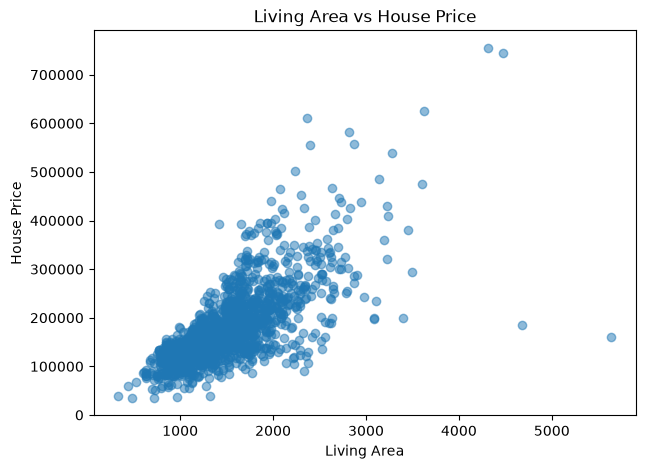

Price Categories:
SalePrice
Medium    490
Low       487
High      483
Name: count, dtype: int64


In [7]:
# Features, Categories, Preprocessing and Visualization

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "FullBath",
    "BedroomAbvGr",
    "YearBuilt",
    "Neighborhood"
]

X = df[features]
y_price = df["SalePrice"]

# Create Low, Medium and High price categories
y_category = pd.qcut(
    y_price,
    q=3,
    labels=["Low", "Medium", "High"]
)

# Numeric and categorical features
numeric_features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "FullBath",
    "BedroomAbvGr",
    "YearBuilt"
]

categorical_features = ["Neighborhood"]

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Visualization
plt.figure(figsize=(7, 5))
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.5)
plt.xlabel("Living Area")
plt.ylabel("House Price")
plt.title("Living Area vs House Price")
plt.show()

print("Price Categories:")
print(y_category.value_counts())

In [8]:
# Train and Apply Both ML Models

# Train-test split for price prediction
X_train, X_test, y_train, y_test = train_test_split(
    X, y_price,
    test_size=0.20,
    random_state=42
)

# Linear Regression
linear_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

price_pred = linear_model.predict(X_test)

# Train-test split for category prediction
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

# Random Forest
rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train_c, y_train_c)

category_pred = rf_model.predict(X_test_c)

print("Both models trained successfully!")

print("\nSample Price Predictions:")
print(price_pred[:5])

print("\nSample Category Predictions:")
print(category_pred[:5])

Both models trained successfully!

Sample Price Predictions:
[140741.65909299 328889.93058383 114611.60266276 180141.07506226
 284695.87202926]

Sample Category Predictions:
['High' 'High' 'Medium' 'Medium' 'Medium']


In [10]:
#Model Evaluation and Comparison

#Linear Regression evaluation
mse = mean_squared_error(y_test, price_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, price_pred)

#Random Forest evaluation
accuracy = accuracy_score(y_test_c, category_pred)

print("FINAL RESULTS")

print("\nLinear Regression - Price Prediction")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

print("\nRandom Forest - Category Prediction")
print("Accuracy:", round(accuracy, 3))

print("\nClassification Report:")
print(classification_report(y_test_c, category_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_c, category_pred))

print("MODEL COMPARISON")
print("Linear Regression R2:", round(r2, 3))
print("Random Forest Accuracy:", round(accuracy, 3))

FINAL RESULTS

Linear Regression - Price Prediction
MSE: 1301515502.15
RMSE: 36076.52
R2 Score: 0.83

Random Forest - Category Prediction
Accuracy: 0.795

Classification Report:
              precision    recall  f1-score   support

        High       0.86      0.92      0.89        97
         Low       0.80      0.78      0.79        97
      Medium       0.71      0.68      0.70        98

    accuracy                           0.79       292
   macro avg       0.79      0.79      0.79       292
weighted avg       0.79      0.79      0.79       292


Confusion Matrix:
[[89  0  8]
 [ 2 76 19]
 [12 19 67]]
MODEL COMPARISON
Linear Regression R2: 0.83
Random Forest Accuracy: 0.795
